# Modeling with a scikit-learn Pipeline

In [1]:
# Import the libraries
import pandas as pd
import numpy as np
from pathlib import Path

# Define the paths (relative to the notebooks folder)
ruta_datos = Path("../data/processed")
ruta_df = ruta_datos / "df_sin_onehot.csv"

# Load the dataframe without one-hot columns, parsing the date column
df = pd.read_csv(ruta_df, parse_dates=["fecha"])

# Check the loaded data
print(df.shape)
df.head()

(2880, 37)


,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,...,unidades_lag_2,unidades_lag_3,unidades_lag_4,unidades_lag_5,unidades_lag_6,unidades_lag_7,unidades_media_movil_7,descuento_porcentaje,precio_competencia,ratio_precio
0,2021-11-01,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,7,115.07,805.49,...,12.0,12.0,7.0,8.0,8.0,6.0,8.857143,0.060870,95.353333,1.206775
1,2021-11-01,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.00,1360.00,...,12.0,9.0,8.0,8.0,10.0,10.0,9.571429,0.740741,113.393333,1.199365
2,2021-11-01,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,85.14,170.28,...,3.0,3.0,2.0,3.0,2.0,2.0,2.571429,0.164706,83.276667,1.022375
3,2021-11-01,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,76.74,153.48,...,3.0,2.0,2.0,2.0,2.0,2.0,2.285714,2.320000,71.843333,1.068158
4,2021-11-01,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,34.89,69.78,...,2.0,2.0,2.0,2.0,2.0,2.0,2.000000,-0.314286,33.490000,1.041804


### Train / validation split by year
The split is chronological (train 2021-2023, validation 2024), never random, so the validation set mimics forecasting a future campaign.

In [2]:
# Split by year: train 2021-2023 and validation 2024
train_df = df[df["año"] <= 2023]
validation_df = df[df["año"] == 2024]

# Check the sizes (2,160 and 720 rows expected)
print(train_df.shape, validation_df.shape)

(2160, 37) (720, 37)


### Column groups
The categorical columns go through the one-hot encoder; the numeric and binary ones pass through untouched. `fecha`, `ingresos` (it is derived from the target, so it would leak it), `producto_id` (an identifier already represented by `nombre`) and the target are left out.

In [3]:
# Define the target and the columns to drop
target = "unidades_vendidas"
cols_descartadas = ["fecha", "ingresos", "producto_id", target]

# Split the predictors into categorical and numeric/binary groups
cols_cat = ["nombre", "categoria", "subcategoria"]
cols_num = [col for col in df.columns if col not in cols_cat + cols_descartadas]
print(len(cols_cat), "categorical columns:", cols_cat)
print(len(cols_num), "numeric or binary columns:", cols_num)

# Build X and y for train and validation (booleans and integers are cast to float, as in the training notebook)
predictoras = cols_cat + cols_num
X_train = train_df[predictoras].copy()
X_val = validation_df[predictoras].copy()
X_train[cols_num] = X_train[cols_num].astype(float)
X_val[cols_num] = X_val[cols_num].astype(float)
y_train = train_df[target]
y_val = validation_df[target]

3 categorical columns: ['nombre', 'categoria', 'subcategoria']
30 numeric or binary columns: ['precio_base', 'es_estrella', 'precio_venta', 'año', 'mes', 'dia_mes', 'dia_semana', 'dia_año', 'semana_año', 'trimestre', 'es_fin_semana', 'es_festivo', 'es_vispera_festivo', 'es_black_friday', 'es_cyber_monday', 'es_semana_black_friday', 'dias_hasta_black_friday', 'es_inicio_mes', 'es_fin_mes', 'unidades_lag_1', 'unidades_lag_2', 'unidades_lag_3', 'unidades_lag_4', 'unidades_lag_5', 'unidades_lag_6', 'unidades_lag_7', 'unidades_media_movil_7', 'descuento_porcentaje', 'precio_competencia', 'ratio_precio']


### Preprocessing with a ColumnTransformer
- `handle_unknown="ignore"`: a product or category never seen in training (e.g. a new product in 2025) is encoded as all zeros instead of raising an error at prediction time.
- `sparse_output=False`: the encoder returns a dense array, which keeps the output as a regular dataframe and is small anyway (44 columns).
- `remainder="passthrough"`: the numeric and binary columns are not transformed.
- `set_output(transform="pandas")`: the transformed data keeps its column names, so we can inspect it and check it.

In [4]:
# Import the scikit-learn pieces
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor

# One-hot encode the categorical columns and pass the rest through
preprocesado = ColumnTransformer(
    transformers=[("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cols_cat)],
    remainder="passthrough",
)

# Keep the column names in the transformed output
preprocesado.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.

### Pipeline with the model
The model uses the same hyperparameters as the conservative `modelo` of the training notebook. Chaining the preprocessing and the model in one object guarantees that the same encoding is applied in training and in prediction.

In [5]:
# Chain the preprocessing and the model (same hyperparameters as `modelo`)
pipeline = Pipeline([
    ("preprocesado", preprocesado),
    ("modelo", HistGradientBoostingRegressor(
        learning_rate=0.03,
        max_iter=500,
        max_depth=5,
        max_leaf_nodes=15,
        min_samples_leaf=40,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )),
])

# Fit on train and predict on validation
pipeline.fit(X_train, y_train)
pred_val = pipeline.predict(X_val)

### Validation metrics
`metricas` is copied from the training notebook. The expected result is the same as the original model: MAE ≈ 1.082 and R² ≈ 0.870.

In [6]:
# Import the metric functions
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Compute the usual forecasting metrics (copied from the training notebook)
def metricas(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "MAPE (%)": np.mean(np.abs((y_real - y_pred) / y_real)) * 100,
        "WMAPE (%)": np.abs(y_real - y_pred).sum() / np.abs(y_real).sum() * 100,
        "R2": r2_score(y_real, y_pred),
    }

# Show the validation and train metrics of the pipeline
pd.DataFrame({
    "Pipeline - validation": metricas(y_val, pred_val),
    "Pipeline - train": metricas(y_train, pipeline.predict(X_train)),
}).T.round(3)

,MAE,RMSE,MAPE (%),WMAPE (%),R2
Pipeline - validation,1.082,2.414,18.994,20.421,0.870
Pipeline - train,0.721,1.487,15.762,13.745,0.953


### Checks on the transformed data
We verify that the transformation produces the 74 expected predictors (44 one-hot + 30 passthrough), that there are no duplicated column names, and that the only missing values are the expected ones: the lags and the moving average, which are empty at the start of each product and year (and `HistGradientBoostingRegressor` handles them natively).

In [7]:
# Transform the training data with the fitted preprocessing step
X_train_t = pipeline[:-1].transform(X_train)

# Check a) the number of transformed columns is 74
print("a) transformed columns:", X_train_t.shape[1], "->", X_train_t.shape[1] == 74)

# Check b) there are no duplicated column names
print("b) no duplicated columns:", not X_train_t.columns.duplicated().any())

# Check c) the only columns with NaN are the lags and the moving average
cols_con_nan = X_train_t.columns[X_train_t.isna().any()].tolist()
cols_nan_esperadas = {c for c in X_train_t.columns if "unidades_lag_" in c or "unidades_media_movil_7" in c}
print("c) columns with NaN:", cols_con_nan)
print("   only expected columns have NaN:", set(cols_con_nan) <= cols_nan_esperadas)

# Check d) the one-hot block has exactly one 1 per categorical variable and row
onehot_t = X_train_t.filter(like="onehot__")
print("d) one-hot columns:", onehot_t.shape[1], "| one 1 per variable and row:", (onehot_t.sum(axis=1) == len(cols_cat)).all())

a) transformed columns: 74 -> True
b) no duplicated columns: True
c) columns with NaN: []
   only expected columns have NaN: True
d) one-hot columns: 44 | one 1 per variable and row: True


### Final pipeline on all rows and saving
The final pipeline is refit on the 2,880 rows (2021-2024) with the same settings, and saved with joblib. Reloading it and comparing predictions confirms that the saved object is complete (encoder and model together).

In [8]:
# Import joblib and sklearn's clone to build an unfitted copy of the pipeline
import joblib
from sklearn.base import clone

# Build the full training set (2021-2024)
X_full = pd.concat([X_train, X_val])
y_full = pd.concat([y_train, y_val])

# Refit an unfitted copy of the pipeline on all the rows
pipeline_final = clone(pipeline)
pipeline_final.fit(X_full, y_full)
print("Training rows:", X_full.shape[0], "| Predictors:", X_full.shape[1])

# Save the final pipeline in the models folder
ruta_modelos = Path("../models")
ruta_modelos.mkdir(parents=True, exist_ok=True)
ruta_pipeline = ruta_modelos / "pipeline_final.joblib"
joblib.dump(pipeline_final, ruta_pipeline)

# Check the saved file by loading it back and comparing its predictions with the in-memory pipeline
pipeline_cargado = joblib.load(ruta_pipeline)
print("Saved pipeline:", ruta_pipeline)
print("Same predictions after loading:", np.allclose(pipeline_cargado.predict(X_full), pipeline_final.predict(X_full)))

Training rows: 2880 | Predictors: 33
Saved pipeline: ..\models\pipeline_final.joblib
Same predictions after loading: True


## Recursive evaluation on 2024

### Recursive forecast vs one-step forecast
The pipeline above predicts each day with the REAL lags (one-step ahead), which is not what happens in November 2025: there the lags only exist for day 1 and every later lag comes from our own predictions. Here we train a pipeline only with 2021-2023 and apply `recursive_forecast` (from `src/forecasting.py`) to November 2024, using the real prices and discounts but the real lags only on day 1. Comparing it with the one-step forecast shows how much accuracy is lost by predicting recursively.

In [9]:
# Make the src package importable from the notebooks folder
import sys
sys.path.append(str(Path("..").resolve()))
from src.forecasting import recursive_forecast

# Train a pipeline only with 2021-2023 (unfitted copy of the pipeline defined above)
pipeline_rec = clone(pipeline)
pipeline_rec.fit(X_train, y_train)

# Take the November 2024 rows with the date and product id needed by the recursion
nov_2024 = validation_df[validation_df["mes"] == 11]
entrada = nov_2024[["fecha", "producto_id"] + predictoras].copy()
entrada[cols_num] = entrada[cols_num].astype(float)

# Recursive forecast: real lags only on day 1, then each prediction feeds the next day
rec = recursive_forecast(pipeline_rec, entrada)

# One-step forecast: real lags on every day
paso = nov_2024[["fecha", "producto_id", target]].copy()
paso["pred_un_paso"] = pipeline_rec.predict(entrada[predictoras])

# Join both forecasts with the real units, one row per product and day
comp = paso.merge(rec[["fecha", "producto_id", "unidades_predichas"]], on=["fecha", "producto_id"]).rename(columns={"unidades_predichas": "pred_recursiva"})
print(comp.shape)

(720, 5)


### Metrics of both approaches
Same validation rows and same `metricas` function for both forecasts.

In [10]:
# Compare the one-step and the recursive forecast on the whole of November 2024
tabla = pd.DataFrame({
    "One-step (real lags)": metricas(comp[target], comp["pred_un_paso"]),
    "Recursive (lags from predictions)": metricas(comp[target], comp["pred_recursiva"]),
}).T[["MAE", "RMSE", "WMAPE (%)", "R2"]].round(3)
tabla

,MAE,RMSE,WMAPE (%),R2
One-step (real lags),1.082,2.414,20.421,0.870
Recursive (lags from predictions),1.419,3.121,26.778,0.783


### MAE by day
The recursive forecast accumulates its own errors, so its MAE should grow with the horizon while the one-step MAE stays flat.

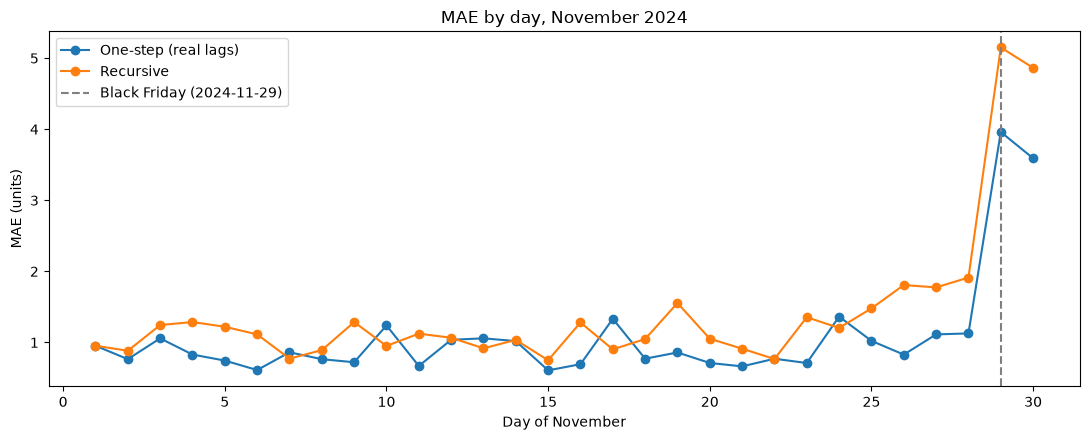

In [11]:
# Import matplotlib for the chart
import matplotlib.pyplot as plt

# Compute the MAE of each day of November (average over the 24 products)
comp["abs_paso"] = (comp[target] - comp["pred_un_paso"]).abs()
comp["abs_rec"] = (comp[target] - comp["pred_recursiva"]).abs()
mae_dia = comp.groupby(comp["fecha"].dt.day)[["abs_paso", "abs_rec"]].mean()

# Plot both curves, marking Black Friday 2024
bf_fecha = nov_2024.loc[nov_2024["es_black_friday"] == 1, "fecha"].iloc[0]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(mae_dia.index, mae_dia["abs_paso"], marker="o", label="One-step (real lags)")
ax.plot(mae_dia.index, mae_dia["abs_rec"], marker="o", label="Recursive")
ax.axvline(bf_fecha.day, color="gray", linestyle="--", label=f"Black Friday ({bf_fecha.date()})")
ax.set_title("MAE by day, November 2024")
ax.set_xlabel("Day of November")
ax.set_ylabel("MAE (units)")
ax.legend()
plt.tight_layout()
plt.show()

### Black Friday 2024
Black Friday is the peak day, so it is where a wrong forecast costs the most. The date is taken from the `es_black_friday` flag of the data.

In [12]:
# Compare real units, one-step and recursive forecast on Black Friday 2024 (per product and total)
bf = comp[comp["fecha"] == bf_fecha]
print("Black Friday:", bf_fecha.date())
resumen_bf = pd.DataFrame({
    "Real": [bf[target].sum()],
    "One-step": [bf["pred_un_paso"].sum()],
    "Recursive": [bf["pred_recursiva"].sum()],
    "MAE one-step": [bf["abs_paso"].mean()],
    "MAE recursive": [bf["abs_rec"].mean()],
}, index=["Total units / MAE per product"]).round(2)
resumen_bf

Black Friday: 2024-11-29


,Real,One-step,Recursive,MAE one-step,MAE recursive
Total units / MAE per product,450,360.88,330.15,3.96,5.15


In [13]:
# Show the days where the recursive MAE starts to separate from the one-step MAE
mae_dia["diferencia"] = mae_dia["abs_rec"] - mae_dia["abs_paso"]
mae_dia.round(3)

,abs_paso,abs_rec,diferencia
fecha,,,
1,0.954,0.954,0.000
2,0.764,0.883,0.118
3,1.057,1.244,0.187
4,0.829,1.287,0.458
5,0.745,1.220,0.476
6,0.611,1.113,0.502
7,0.861,0.773,-0.089
8,0.764,0.891,0.127
9,0.721,1.286,0.565


### Conclusions: cost of predicting recursively
- **Overall degradation (November 2024, 720 rows):** MAE goes from 1.082 to 1.419 (+0.337 units, +31%), WMAPE from 20.4% to 26.8% (+6.4 points), RMSE from 2.414 to 3.121 and R2 from 0.870 to 0.783. Day 1 is identical in both (MAE 0.954), as expected, because it uses the real lags.
- **When it starts to show:** the gap is positive from day 2 (+0.12 MAE) but noisy day by day, with an average of about +0.20 MAE over days 1-10 and again over days 11-20. It becomes clear only in the last ten days (average +0.61 MAE over days 21-30), and from day 25 it is always above +0.45 (+0.98 on day 26, +1.19 on day 29, +1.27 on day 30).
- **Black Friday (2024-11-29):** real 450 units, one-step 360.9 (-19.8%), recursive 330.2 (-26.6%). MAE per product is 3.96 one-step and 5.15 recursive. Most of the Black Friday error already exists in the one-step forecast (the model underestimates the peak even with real lags); the recursion adds about 1.2 units of MAE per product on top.
- **Reading:** the November 2025 forecast, which is fully recursive from day 2, should be expected to be about 30% worse in MAE than the 1.08 measured with real lags, and the end of the month (Black Friday week) is where it is least reliable.